# Cuckoo Search for Forest Fire Monitoring: Sensor Placement

## Objective
Optimize the placement of a limited number of forest fire sensors to maximize the coverage of high-risk forest areas.

This is a **simulation** using a synthetic fire-risk map. It is not a fire prediction model or real-world deployment system.

## 1. Import Libraries

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import math

np.random.seed(42)

## 2. Create a Simulated Forest Risk Map

We represent the forest as a 10 × 10 grid. Each cell has a risk score between 0 and 1. Simulated risk hotspots are created using Gaussian-like distance patterns.

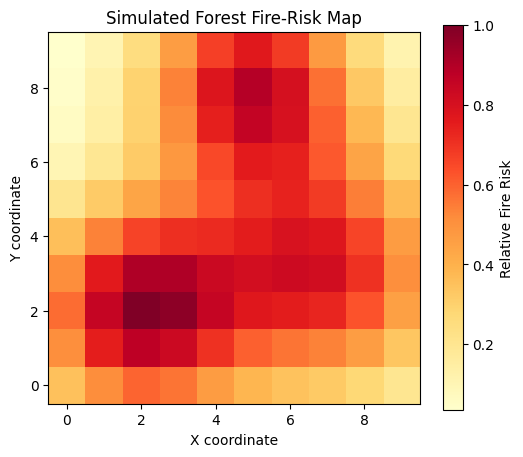

In [16]:
grid_size = 10
x_coords, y_coords = np.meshgrid(np.arange(grid_size), np.arange(grid_size))
risk_map = np.zeros((grid_size, grid_size), dtype=float)

# Simulated risk hotspots: (x, y, intensity, spread)
hotspots = [
    (2, 2, 1.0, 2.0),
    (7, 3, 0.8, 2.2),
    (5, 8, 0.9, 2.0)
]

for hx, hy, intensity, spread in hotspots:
    risk_map += intensity * np.exp(
        -((x_coords - hx)**2 + (y_coords - hy)**2) / (2 * spread**2)
    )

# Normalize risk values to range 0..1
risk_map = risk_map / risk_map.max()

plt.figure(figsize=(6, 5))
plt.imshow(risk_map, origin="lower", cmap="YlOrRd")
plt.colorbar(label="Relative Fire Risk")
plt.title("Simulated Forest Fire-Risk Map")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.show()

## 3. Define Inputs and Parameters

Each grid cell is a candidate sensor location. We select a fixed number of sensors. A sensor covers grid cells within the specified Euclidean distance (coverage radius).

In [17]:
num_sensors = 8
coverage_radius = 2.5

num_nests = 25
discovery_probability = 0.25  # fraction of nests to abandon
max_iterations = 100

# Flatten grid and risk values for convenient calculations
candidate_points = np.array([
    (x, y) for y in range(grid_size) for x in range(grid_size)
])
risk_values = risk_map.flatten()
num_candidates = len(candidate_points)

print("Forest grid:", grid_size, "x", grid_size)
print("Candidate locations:", num_candidates)
print("Sensors available:", num_sensors)
print("Coverage radius:", coverage_radius)
print("Number of nests:", num_nests)
print("Discovery probability:", discovery_probability)
print("Maximum iterations:", max_iterations)

Forest grid: 10 x 10
Candidate locations: 100
Sensors available: 8
Coverage radius: 2.5
Number of nests: 25
Discovery probability: 0.25
Maximum iterations: 100


## 4. Fitness Function

A nest is represented by a score vector over all candidate locations. The locations with the highest scores are selected as sensor sites.

Fitness is the fraction of total fire-risk weight covered by at least one sensor:

**Fitness = Covered fire-risk weight / Total fire-risk weight**

The fitness ranges from 0 to 1. Higher values indicate better coverage of the risk map.

In [18]:
def get_sensor_locations(solution):
    # Select the candidate locations with the highest solution scores
    selected_indices = np.argsort(solution)[-num_sensors:]
    return candidate_points[selected_indices]


def calculate_fitness(solution):
    sensor_locations = get_sensor_locations(solution)

    # Distances from every forest cell to every selected sensor
    distances = np.sqrt(
        (candidate_points[:, None, 0] - sensor_locations[None, :, 0])**2 +
        (candidate_points[:, None, 1] - sensor_locations[None, :, 1])**2
    )

    # A cell is covered if at least one sensor is within its radius
    covered = np.any(distances <= coverage_radius, axis=1)

    covered_risk = risk_values[covered].sum()
    total_risk = risk_values.sum()

    return covered_risk / total_risk

## 5. Lévy Flight Helper

Lévy flights generate occasional larger movements along with smaller movements, helping the search explore new candidate solutions. We use Mantegna's method to generate a Lévy-like step.

In [19]:
def levy_flight(size, beta=1.5):

    sigma_u = (
        math.gamma(1 + beta) * np.sin(np.pi * beta / 2) /
        (math.gamma((1 + beta) / 2) * beta *
         2 ** ((beta - 1) / 2))
    ) ** (1 / beta)

    u = np.random.normal(0, sigma_u, size=size)
    v = np.random.normal(0, 1, size=size)

    return u / (np.abs(v) ** (1 / beta))

## 6. Initialize Nests

Each nest is a randomly generated score vector. The top-scoring candidate locations in each vector represent that nest's sensor placement.

In [20]:
nests = np.random.rand(num_nests, num_candidates)

fitness_values = np.array([
    calculate_fitness(nest) for nest in nests
])

best_index = np.argmax(fitness_values)
best_nest = nests[best_index].copy()
best_fitness = fitness_values[best_index]

print("Initial best fitness:", round(best_fitness, 4))

Initial best fitness: 0.9406


## 7. Run the Cuckoo Search Algorithm

At each iteration:
1. Generate a new candidate using Lévy-flight perturbation.
2. Evaluate its fitness.
3. Randomly select a nest and replace it if the new solution is better.
4. Abandon a fraction of nests and replace them with random solutions.
5. Preserve the best solution found so far.

In [21]:
fitness_history = []

for iteration in range(max_iterations):
    # Generate new solutions by Lévy-flight perturbation
    for i in range(num_nests):
        step = levy_flight(num_candidates)
        new_solution = nests[i] + 0.05 * step

        new_fitness = calculate_fitness(new_solution)

        # Compare against a randomly selected nest
        j = np.random.randint(num_nests)
        if new_fitness > fitness_values[j]:
            nests[j] = new_solution
            fitness_values[j] = new_fitness

    # Abandon a fraction of the poorer nests
    num_abandoned = max(1, int(discovery_probability * num_nests))
    poor_indices = np.argsort(fitness_values)[:num_abandoned]

    nests[poor_indices] = np.random.rand(
        num_abandoned, num_candidates
    )

    fitness_values[poor_indices] = np.array([
        calculate_fitness(nest) for nest in nests[poor_indices]
    ])

    # Preserve the best nest found so far
    current_best_index = np.argmax(fitness_values)
    current_best_fitness = fitness_values[current_best_index]

    if current_best_fitness > best_fitness:
        best_fitness = current_best_fitness
        best_nest = nests[current_best_index].copy()

    fitness_history.append(best_fitness)

print("Optimization completed.")

Optimization completed.


## 8. Plot Fitness Progress

This graph shows the best fire-risk coverage fitness found across iterations.

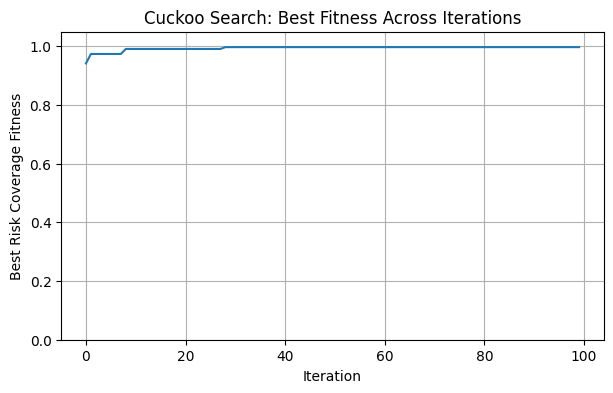

In [22]:
plt.figure(figsize=(7, 4))
plt.plot(fitness_history)
plt.title("Cuckoo Search: Best Fitness Across Iterations")
plt.xlabel("Iteration")
plt.ylabel("Best Risk Coverage Fitness")
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

## 9. Display Optimized Sensor Placement

The red/orange map shows relative fire risk. Blue markers show the sensor locations selected by the best nest. The circles indicate each sensor's coverage radius.

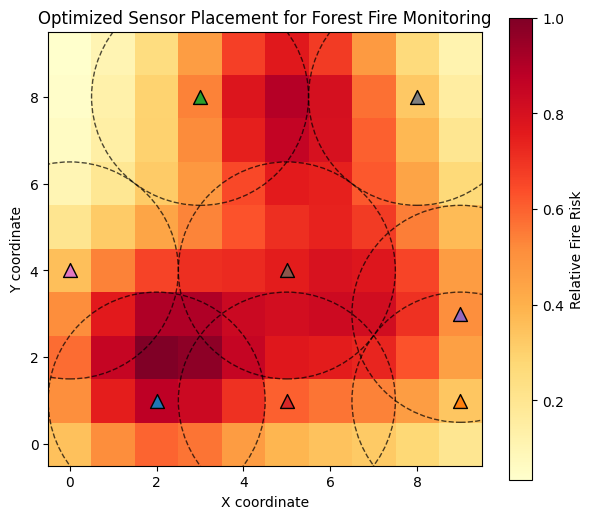

In [23]:
best_sensor_locations = get_sensor_locations(best_nest)

plt.figure(figsize=(7, 6))
plt.imshow(risk_map, origin="lower", cmap="YlOrRd")
plt.colorbar(label="Relative Fire Risk")

for sx, sy in best_sensor_locations:
    plt.scatter(sx, sy, marker="^", s=100, edgecolor="black", label="Sensor" if (sx, sy) == tuple(best_sensor_locations[0]) else "")
    circle = plt.Circle((sx, sy), coverage_radius, fill=False, linestyle="--", alpha=0.7)
    plt.gca().add_patch(circle)

plt.title("Optimized Sensor Placement for Forest Fire Monitoring")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.xlim(-0.5, grid_size - 0.5)
plt.ylim(-0.5, grid_size - 0.5)
plt.show()

## 10. Final Results

In [24]:
print("=== CUCKOO SEARCH RESULTS ===")
print("Number of sensors:", num_sensors)
print("Coverage radius:", coverage_radius)
print("Best risk coverage fitness:", round(best_fitness, 4))
print("Estimated percentage of fire-risk weight covered:",
      round(best_fitness * 100, 2), "%")
print("\\nSelected sensor coordinates:")
for location in best_sensor_locations:
    print(tuple(location))

=== CUCKOO SEARCH RESULTS ===
Number of sensors: 8
Coverage radius: 2.5
Best risk coverage fitness: 0.9975
Estimated percentage of fire-risk weight covered: 99.75 %
\nSelected sensor coordinates:
(np.int64(2), np.int64(1))
(np.int64(9), np.int64(1))
(np.int64(3), np.int64(8))
(np.int64(5), np.int64(1))
(np.int64(9), np.int64(3))
(np.int64(5), np.int64(4))
(np.int64(0), np.int64(4))
(np.int64(8), np.int64(8))


## 11. Conclusion

The Cuckoo Search algorithm was used to optimize sensor placement in a simulated forest environment. Each nest represented a candidate deployment, and fitness measured the proportion of fire-risk weight covered by sensors. Lévy-flight exploration, solution comparison, nest abandonment and preservation of the best solution helped search for improved deployments.

**Limitations:** This is a simplified simulation. It assumes a fixed coverage radius and a synthetic risk map. Real deployment would require geographic data, sensor characteristics, terrain, communication constraints, power budgets and validation.